In [20]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [36]:
df = pd.read_csv("top250-00-19.csv")

                Name        Position  Age     Team_from     League_from  \
0          Luís Figo    Right Winger   27  FC Barcelona          LaLiga   
1      Hernán Crespo  Centre-Forward   25         Parma         Serie A   
2      Marc Overmars     Left Winger   27       Arsenal  Premier League   
3  Gabriel Batistuta  Centre-Forward   31    Fiorentina         Serie A   
4     Nicolas Anelka  Centre-Forward   21   Real Madrid          LaLiga   

        Team_to League_to     Season  Market_value  Transfer_fee  
0   Real Madrid    LaLiga  2000-2001           NaN      60000000  
1         Lazio   Serie A  2000-2001           NaN      56810000  
2  FC Barcelona    LaLiga  2000-2001           NaN      40000000  
3       AS Roma   Serie A  2000-2001           NaN      36150000  
4      Paris SG   Ligue 1  2000-2001           NaN      34500000  
Index(['Name', 'Position', 'Age', 'Team_from', 'League_from', 'Team_to',
       'League_to', 'Season', 'Market_value', 'Transfer_fee'],
      dtype

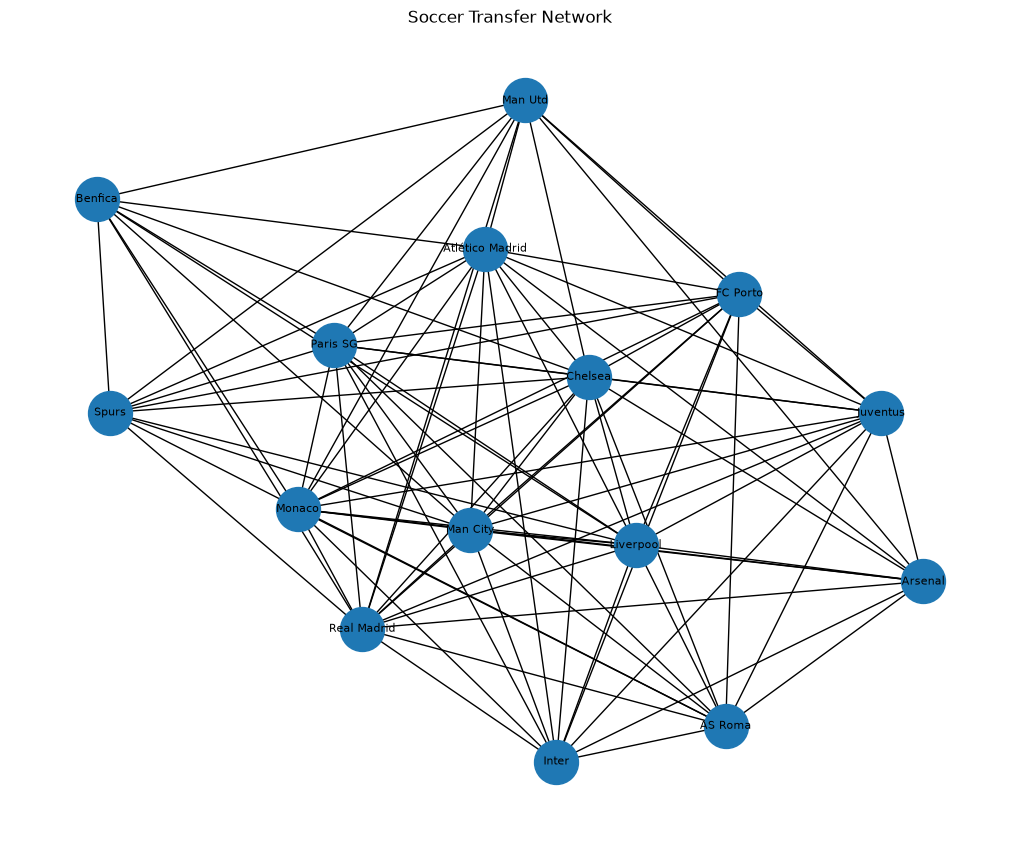

In [37]:
print(df.head())
print(df.columns)

# Create graph
g = nx.Graph()

# Add edges between the selling club and buying club
for index, row in df.iterrows():
    team_from = row["Team_from"]
    team_to = row["Team_to"]

    if pd.notna(team_from) and pd.notna(team_to):
        g.add_edge(team_from, team_to)

# Basic graph information
print("Number of nodes:", g.number_of_nodes())
print("Number of edges:", g.number_of_edges())

# Degree centrality
centrality = nx.degree_centrality(g)

# Sort clubs from highest to lowest centrality
important_clubs = sorted(
    centrality,
    key=centrality.get,
    reverse=True
)

# Print top 10 clubs
print("\nTop 10 Clubs")

for club in important_clubs[:10]:
    print(
        club,
        "Centrality:",
        round(centrality[club], 3),
        "Degree:",
        g.degree(club)
    )

# Create a simple table
top_clubs = []

for club in important_clubs[:10]:
    top_clubs.append([
        club,
        g.degree(club),
        round(centrality[club], 3)
    ])

table = pd.DataFrame(
    top_clubs,
    columns=["Club", "Degree", "Degree Centrality"]
)

print(table)

# Save table
table.to_csv("top_clubs.csv", index=False)

# Make a graph using only the top 15 clubs
top15 = important_clubs[:15]

small_graph = g.subgraph(top15)

plt.figure(figsize=(10, 8))

nx.draw(
    small_graph,
    with_labels=True,
    node_size=1000,
    font_size=8
)

plt.title("Soccer Transfer Network")
plt.show()

In [39]:
import networkx as nx

g = nx.Graph()

for index, row in df.iterrows():
    team_from = row["Team_from"]
    team_to = row["Team_to"]

    if pd.notna(team_from) and pd.notna(team_to):
        g.add_edge(team_from, team_to)

print("Nodes:", g.number_of_nodes())
print("Edges:", g.number_of_edges())

Nodes: 615
Edges: 3354


In [40]:
centrality = nx.degree_centrality(g)

important_clubs = sorted(
    centrality,
    key=centrality.get,
    reverse=True
)

for club in important_clubs[:10]:
    print(club, round(centrality[club], 3), g.degree(club))

Spurs 0.138 85
Chelsea 0.132 81
Liverpool 0.129 79
FC Porto 0.127 78
Man City 0.124 76
Inter 0.122 75
Atlético Madrid 0.117 72
Arsenal 0.107 66
Monaco 0.107 66
Juventus 0.104 64


In [41]:
top_clubs = []

for club in important_clubs[:10]:
    top_clubs.append([
        club,
        g.degree(club),
        round(centrality[club], 3)
    ])

table = pd.DataFrame(
    top_clubs,
    columns=["Club", "Degree", "Degree Centrality"]
)

table

,Club,Degree,Degree Centrality
0,Spurs,85,0.138
1,Chelsea,81,0.132
2,Liverpool,79,0.129
3,FC Porto,78,0.127
4,Man City,76,0.124
5,Inter,75,0.122
6,Atlético Madrid,72,0.117
7,Arsenal,66,0.107
8,Monaco,66,0.107
9,Juventus,64,0.104


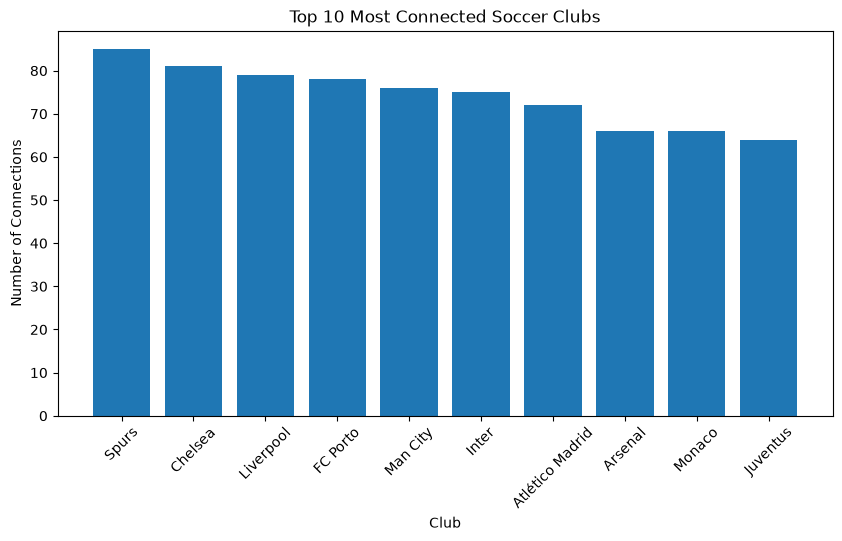

In [42]:
import matplotlib.pyplot as plt

top10 = table

plt.figure(figsize=(10, 5))

plt.bar(top10["Club"], top10["Degree"])

plt.xlabel("Club")
plt.ylabel("Number of Connections")
plt.title("Top 10 Most Connected Soccer Clubs")

plt.xticks(rotation=45)

plt.show()